In [1]:
import os
os.environ["TORCHDYNAMO_DISABLE"] = "1"
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import face_alignment
from scipy.spatial import Delaunay

In [2]:
def addpoints(image):

    detector = face_alignment.FaceAlignment(face_alignment.LandmarksType.TWO_D, device="cpu")
    h, w = image.shape[:2]
    scale = 800 / max(h, w)
    image = cv.resize(image, (int(w*scale), int(h*scale)))
    image=cv.cvtColor(image, cv.COLOR_BGR2RGB)
    landmarks = detector.get_landmarks(image)
    if landmarks is not None:
        for landmark in landmarks:
            for (x, y) in landmark:
                cv.circle(image, (int(x), int(y)), 2, (0, 255, 0), -1)
        return image, landmarks
    else: 
        print("No landmarks detected in the image.")
        return None



def draw_image_with_landmarks(image, landmarks):
    image1 = image.copy()
    for x, y in landmarks[0]:
        cv.circle(image1, (int(x), int(y)), 2, (0, 255, 0), -1)
    plt.axis('off')
    plt.imshow(image1)
    plt.show()


In [3]:
def DelaunayTriangulation(landmarks):
    coordinates = landmarks[0]
    triangle_mesh = Delaunay(coordinates)
    return coordinates, triangle_mesh

def draw_delaunay(image, coordinates, triangle_mesh):
    delaunay_image = image.copy()
    for triangle in triangle_mesh.simplices:
        triangle = coordinates[triangle].astype(np.int32).reshape((-1, 1, 2))
        cv.polylines(delaunay_image, [triangle], isClosed=True, color=(255, 0, 0), thickness=1)
    plt.axis('off')
    plt.imshow(delaunay_image)
    plt.show()

c:\Users\linwi\miniconda3\envs\impro26\lib\site-packages\face_alignment\api.py:130: UserWarning: Compiling face alignment model (one-time cost). Subsequent runs will be faster.
  warnings.warn(


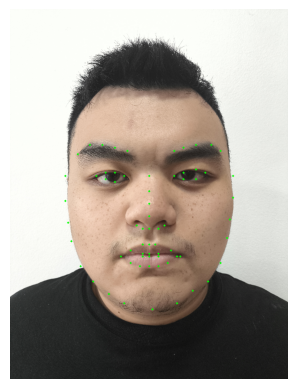

c:\Users\linwi\miniconda3\envs\impro26\lib\site-packages\face_alignment\api.py:130: UserWarning: Compiling face alignment model (one-time cost). Subsequent runs will be faster.
  warnings.warn(


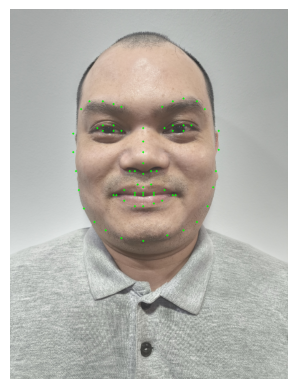

In [4]:
im1 = cv.imread('Faces/Face1.jpg')
im1, landmarks1 = addpoints(im1)
draw_image_with_landmarks(im1, landmarks1) 
im2 = cv.imread('Faces/Face2.jpg')
im2, landmarks2 = addpoints(im2)
draw_image_with_landmarks(im2, landmarks2)

average_mesh=[(landmarks1[0]+landmarks2[0])/2]
coordinates, triangle_mesh = DelaunayTriangulation(average_mesh)

In [30]:
def interpolate_matrices(before_matrix, after_matrix, num_steps):
    for i in range(num_steps+1):
        weight=i/num_steps
        output=((1-(weight))*before_matrix)+((weight)*after_matrix)
        yield output

def compute_triangle_mesh(intermediate_matrices,triangle_mesh):
    triangle=triangle_mesh.simplices
    for frame in intermediate_matrices:
        frame_mesh=frame[triangle]
        yield frame_mesh

intermediate_matrices = list(interpolate_matrices(landmarks1[0], landmarks2[0], num_steps=5))
intermediate_matrices=np.array(intermediate_matrices)
frame_meshes=list(compute_triangle_mesh(intermediate_matrices,triangle_mesh))
frame_meshes=np.array(frame_meshes)
print(intermediate_matrices.shape)
print(frame_meshes.shape)

    



(6, 68, 2)
(6, 112, 3, 2)
